# setup + imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import json
from scipy.io import wavfile
from scipy.fft import dct

In [2]:
train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')

def loadwav(path):
    sr, x = wavfile.read(path)
    # x este np.int16 si are ndim = 1
    x = x.astype(np.float32) / (2**15)
    return sr, x

def fixlen(x, n):
    if len(x) >= n: 
        return x[:n]
    out = np.zeros(n, dtype=np.float32)
    out[:len(x)] = x
    return out

waves = []
for p in train_data['path']:
    sr, x = loadwav(p)
    waves.append(x)
    

# data exploration

In [3]:
lengths = []
for i in range(len(waves)):
  lengths.append(len(waves[i]))
print(pd.Series(lengths).describe())

count     400.000000
mean     1288.292500
std       150.240866
min      1024.000000
25%      1165.000000
50%      1279.500000
75%      1416.000000
max      1536.000000
dtype: float64


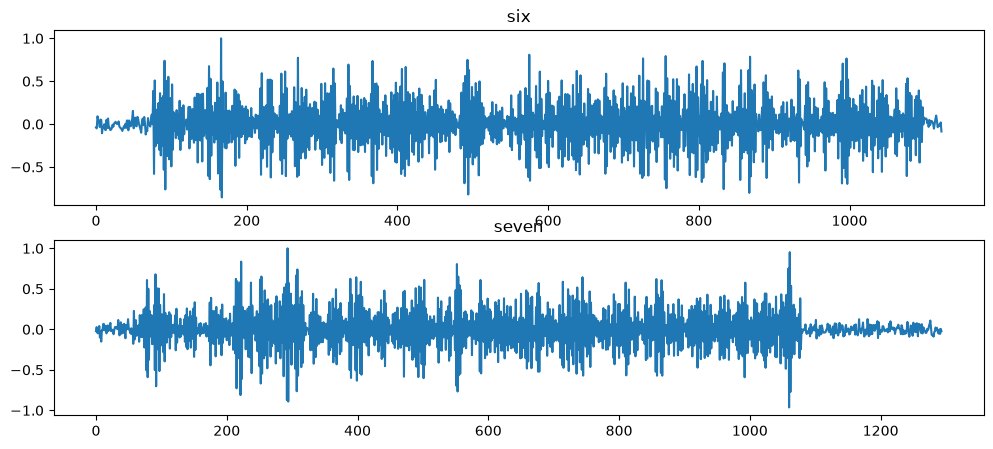

In [4]:
y = train_data['answer'].astype(int)

i6 = -1
i7 = -1
ok = 0
for i in range(len(train_data)):
    if y[i]==6 and i6==-1:
        i6 = i
        ok += 1
    if y[i]==7 and i7==-1:
        i7 = i
        ok += 1
    if ok == 2:
        break

plt.figure(figsize=(12, 5))
plt.subplot(2, 1, 1)          
plt.plot(waves[i6])
plt.title('six')
plt.subplot(2, 1, 2)          
plt.plot(waves[i7])
plt.title('seven')
plt.show()

In [5]:
print(min(lengths), max(lengths))
print(sr)

1024 1536
1024


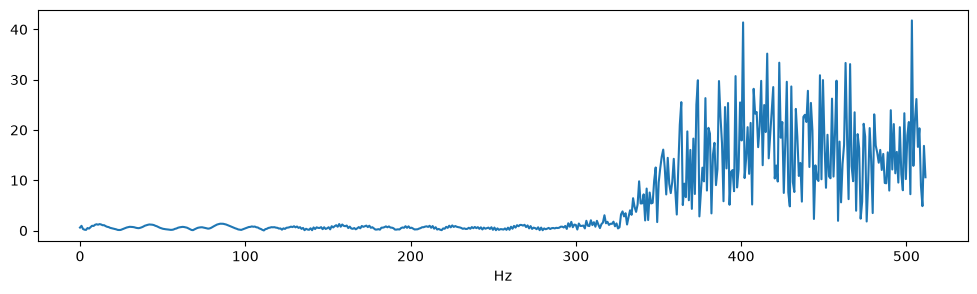

In [6]:
x = waves[i6]
spec = np.abs(np.fft.rfft(x))
freqs = np.fft.rfftfreq(len(x), d=1 / sr)

plt.figure(figsize=(12, 3))
plt.plot(freqs, spec)
plt.xlabel('Hz')
plt.show()

# data cleaning

In [7]:
def lowpass(x, sr, thr):
    X = np.fft.rfft(x)
    freqs = np.fft.rfftfreq(len(x), d=1/sr)
    X[freqs > thr] = 0
    return np.fft.irfft(X, len(x)).astype(np.float32)
    

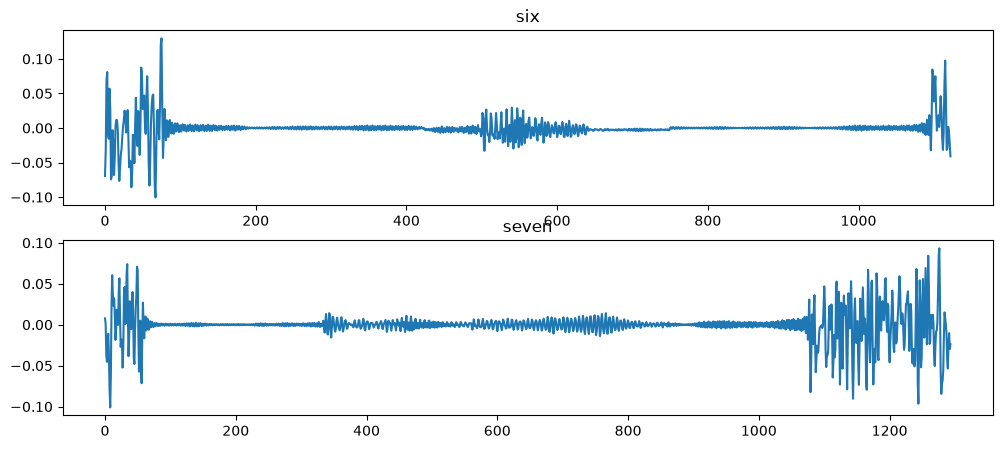

In [8]:
thr = 300

plt.figure(figsize=(12, 5))
plt.subplot(2, 1, 1)          
plt.plot(lowpass(waves[i6], sr, thr))
plt.title('six')
plt.subplot(2, 1, 2)          
plt.plot(lowpass(waves[i7], sr, thr))
plt.title('seven')
plt.show()

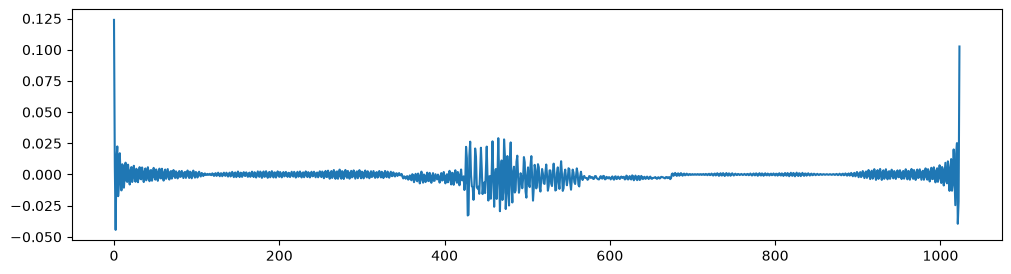

In [9]:
def crop_clip(x, sr, n=1024):
    high = x - lowpass(x, sr, 350)          # only the noise above 350 Hz is left
    sq = high ** 2
    best_s = 0
    best_e = -1
    for s in range(0, len(x) - n + 1):
        e = sq[s:s + n].sum()               # noise energy in this window
        if e > best_e:
            best_e = e
            best_s = s
    return x[best_s:best_s + n], best_s

# check: the loud ends should be gone
clip, s = crop_clip(waves[i6], sr)
plt.figure(figsize=(12, 3))
plt.plot(lowpass(clip, sr, 300))
plt.show()

# model - astea de sub nu sunt scrise de mine lowkey

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

def crop(x, n=1024):
    # the window of n samples with the most energy = the real clip
    best_s = 0
    best_e = -1
    for s in range(0, len(x) - n + 1):
        e = np.sum(x[s:s+n] ** 2)
        if e > best_e:
            best_e = e
            best_s = s
    return x[best_s:best_s+n]

N_FFT = 128
HOP = 32
window = np.hanning(N_FFT)

def features(x):
    x = lowpass(crop(x), sr, 300)
    # spectrogram: FFT of short overlapping pieces
    n_frames = 1 + (len(x) - N_FFT) // HOP
    S = np.zeros((N_FFT // 2 + 1, n_frames))
    for t in range(n_frames):
        frame = x[t*HOP : t*HOP + N_FFT] * window
        S[:, t] = np.abs(np.fft.rfft(frame))
    S = S[:38]                      # rows below 300 Hz (each row is 8 Hz)
    logS = np.log(S + 1e-6)
    return np.concatenate([logS.mean(axis=1), logS.std(axis=1), logS.reshape(-1)])

feats = []
for i in range(len(waves)):
    feats.append(features(waves[i]))
X = np.array(feats)
y = np.array(y)
print(X.shape)

(400, 1178)


In [11]:
fit_idx, val_idx = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=0)
scaler = StandardScaler().fit(X[fit_idx])
model = LogisticRegression(C=0.1, max_iter=2000).fit(scaler.transform(X[fit_idx]), y[fit_idx])
print('val acc', accuracy_score(y[val_idx], model.predict(scaler.transform(X[val_idx]))))

val acc 0.9375


# submission

In [12]:
scaler = StandardScaler().fit(X)
model = LogisticRegression(C=0.1, max_iter=2000).fit(scaler.transform(X), y)

feats = []
for p in test_data['path']:
    sr, x = loadwav(p)
    feats.append(features(x))
X_test = np.array(feats)
pred = model.predict(scaler.transform(X_test))

sub = pd.DataFrame({'subtaskID': test_data['subtaskID'], 'datapointID': test_data['datapointID'], 'answer': pred})
print(sub.head())
sub.to_csv('submission.csv', index=False)

   subtaskID  datapointID  answer
0          1            1       6
1          1            2       7
2          1            3       6
3          1            4       6
4          1            5       7
